# Proyecto integrador - Predicción de regalías mineras (ANM)

Maestría en Ciencia de Datos - UPB
Estudiante: Jairo

Dataset: "ANM Volumen de Explotación de Minerales Asociados a Pagos de Regalías", publicado por la Agencia Nacional de Minería en Datos Abiertos Colombia: https://www.datos.gov.co/d/r85m-vv6c

El trabajo sigue las fases de CRISP-DM. El problema es de regresión: estimar cuánto se paga de regalías según el mineral, el volumen explotado, el departamento y el periodo.

In [1]:
# en Colab hay que instalar ydata-profiling primero
# !pip install ydata-profiling

import os
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy import stats

from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV, RandomizedSearchCV
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import mutual_info_regression
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import LinearSVR
from sklearn.ensemble import VotingRegressor, BaggingRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

os.makedirs("artifacts/figs", exist_ok=True)
os.makedirs("model", exist_ok=True)

## 1. Entendimiento del negocio

Las regalías son lo que pagan las empresas y los productores mineros al Estado por sacar minerales del subsuelo. La ANM recibe las declaraciones de producción (volumen por mineral, municipio y trimestre) y con eso liquida y fiscaliza el pago.

Para fiscalizar hay que revisar si lo que se pagó tiene sentido para el volumen que se declaró. Eso depende de los precios base de cada mineral, que cambian cada periodo, y se revisa casi siempre a mano. La idea del proyecto es entrenar un modelo que, con el mineral, el volumen, el departamento, el año, el trimestre y el tipo de productor, estime la regalía esperada. Si un pago real se aleja mucho de esa estimación, vale la pena revisarlo.

Objetivos de minería de datos:
1. Llegar a un R2 de al menos 0,90 y un RMSE menor a 0,6 sobre log(regalías) en el conjunto de prueba.
2. Comparar cinco modelos clásicos y tres de ensamble (votación, bagging y boosting), ajustando hiperparámetros con validación cruzada sobre el 70 % de entrenamiento.
3. Publicar el mejor modelo en una app de Streamlit.

Como las regalías van desde miles de pesos hasta más de un billón, se trabaja con el logaritmo de la variable objetivo. La métrica principal es el RMSE en esa escala, y también se reportan MAE y R2.

## 2. Entendimiento de los datos

In [2]:
ruta_local = "data/regalias_anm_raw.csv"
url = "https://www.datos.gov.co/resource/r85m-vv6c.csv?$limit=200000"

# si no está el archivo local se descarga de la API de datos.gov.co
if os.path.exists(ruta_local):
    raw = pd.read_csv(ruta_local, dtype=str)
else:
    raw = pd.read_csv(url, dtype=str)
    os.makedirs("data", exist_ok=True)
    raw.to_csv(ruta_local, index=False)

print(raw.shape)
raw.head()

(79151, 15)


,codigo_dane,nombre_municipio,nombre_departamento,recurso_natural,id_nombre_del_proyecto2,nombre_del_proyecto,periodicidad2,periodo_liquidado2,trimestre,a_o_liquidado,unidad_medida,contraprestacion,regalias_pagadas,volumenes_de_explotacion,min_agrupado2
0,05001,Medellin,Antioquia,ARCILLAS,VARIOS,PRODUCTORES,TRIMESTRAL,12,Trimestre 4,2018,TONELADAS,REGALIAS,"614,258.00",- 0,Arcillas (Ton)
1,05001,Medellin,Antioquia,ARCILLAS CERAMICAS,VARIOS,PRODUCTORES,TRIMESTRAL,3,Trimestre 1,2025,TONELADAS,REGALIAS,"1,721,567.00","6,732.20",Arcillas (Ton)
2,05001,Medellin,Antioquia,ARCILLAS CERAMICAS,VARIOS,PRODUCTORES,TRIMESTRAL,3,Trimestre 1,2026,TONELADAS,REGALIAS,"982,464.00","3,660.00",Arcillas (Ton)
3,05001,Medellin,Antioquia,ARCILLAS CERAMICAS,VARIOS,PRODUCTORES,TRIMESTRAL,12,Trimestre 4,2014,TONELADAS,REGALIAS,"2,036,781.00","14,381.00",Arcillas (Ton)
4,05001,Medellin,Antioquia,ARCILLAS CERAMICAS,VARIOS,PRODUCTORES,TRIMESTRAL,12,Trimestre 4,2022,TONELADAS,REGALIAS,"10,625,362.00","44,151.39",Arcillas (Ton)


In [3]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 79151 entries, 0 to 79150
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   codigo_dane               79151 non-null  object
 1   nombre_municipio          79151 non-null  object
 2   nombre_departamento       79151 non-null  object
 3   recurso_natural           79151 non-null  object
 4   id_nombre_del_proyecto2   79151 non-null  object
 5   nombre_del_proyecto       79151 non-null  object
 6   periodicidad2             79151 non-null  object
 7   periodo_liquidado2        79151 non-null  object
 8   trimestre                 79151 non-null  object
 9   a_o_liquidado             79151 non-null  object
 10  unidad_medida             79151 non-null  object
 11  contraprestacion          79151 non-null  object
 12  regalias_pagadas          79151 non-null  object
 13  volumenes_de_explotacion  79151 non-null  object
 14  min_agrupado2         

In [4]:
raw.nunique().sort_values()

periodicidad2                   1
contraprestacion                2
trimestre                       4
unidad_medida                   6
periodo_liquidado2             12
a_o_liquidado                  15
min_agrupado2                  28
nombre_departamento            32
nombre_del_proyecto            51
id_nombre_del_proyecto2        53
recurso_natural                80
codigo_dane                   888
nombre_municipio              888
volumenes_de_explotacion    57917
regalias_pagadas            77076
dtype: int64

### Diccionario de datos
Todas las columnas llegan como texto, incluso las numéricas. Las que quedan como entrada se explican más abajo.

In [5]:
diccionario = pd.DataFrame({
    "Variable": ["codigo_dane", "nombre_municipio", "nombre_departamento", "recurso_natural",
                 "id_nombre_del_proyecto2", "nombre_del_proyecto", "periodicidad2", "periodo_liquidado2",
                 "trimestre", "a_o_liquidado", "unidad_medida", "contraprestacion", "regalias_pagadas",
                 "volumenes_de_explotacion", "min_agrupado2"],
    "Descripción": ["Código DANE del municipio", "Municipio productor (888 valores)", "Departamento productor",
                    "Mineral específico (80 valores)", "Código del título o proyecto, VARIOS para pequeños productores",
                    "Nombre del proyecto, PRODUCTORES cuando son productores agregados", "Periodicidad (siempre TRIMESTRAL)",
                    "Mes de cierre del periodo liquidado (1 a 12)", "Trimestre liquidado", "Año liquidado (2012 a 2026)",
                    "Unidad del volumen (t, m3, g, kg, lb, quilates)", "REGALIAS o COMPENSACIÓN", "Valor pagado en pesos",
                    "Cantidad explotada en la unidad del mineral", "Mineral agrupado con su unidad (28 valores)"],
    "Tipo": ["Cat", "Cat", "Cat", "Cat", "Cat", "Cat", "Cat", "Num", "Cat (se pasa a Num)", "Num", "Cat", "Cat", "Num", "Num", "Cat"],
    "Uso": ["Descartada", "Descartada", "Entrada", "Descartada (se usa min_agrupado2)", "Para crear gran_proyecto",
            "Para crear gran_proyecto", "Descartada (constante)", "Descartada (repite el trimestre)", "Entrada", "Entrada",
            "Descartada (la define el mineral)", "Filtro (solo REGALIAS)", "Salida (objetivo)", "Entrada", "Entrada"],
})
diccionario.to_csv("artifacts/diccionario.csv", index=False)
diccionario

,Variable,Descripción,Tipo,Uso
0,codigo_dane,Código DANE del municipio,Cat,Descartada
1,nombre_municipio,Municipio productor (888 valores),Cat,Descartada
2,nombre_departamento,Departamento productor,Cat,Entrada
3,recurso_natural,Mineral específico (80 valores),Cat,Descartada (se usa min_agrupado2)
4,id_nombre_del_proyecto2,"Código del título o proyecto, VARIOS para pequ...",Cat,Para crear gran_proyecto
5,nombre_del_proyecto,"Nombre del proyecto, PRODUCTORES cuando son pr...",Cat,Para crear gran_proyecto
6,periodicidad2,Periodicidad (siempre TRIMESTRAL),Cat,Descartada (constante)
7,periodo_liquidado2,Mes de cierre del periodo liquidado (1 a 12),Num,Descartada (repite el trimestre)
8,trimestre,Trimestre liquidado,Cat (se pasa a Num),Entrada
9,a_o_liquidado,Año liquidado (2012 a 2026),Num,Entrada


### Reglas de calidad
Los números vienen con coma de miles ("1,721,567.00") y cuando el volumen es cero aparece como "- 0". Primero se convierten a número y luego se revisa qué porcentaje de filas cumple cada regla.

In [6]:
def a_numero(serie):
    serie = serie.str.replace(",", "", regex=False).str.replace(" ", "", regex=False)
    return pd.to_numeric(serie, errors="coerce")

df = raw.copy()
df["regalias"] = a_numero(df["regalias_pagadas"])
df["volumen"] = a_numero(df["volumenes_de_explotacion"])
df["anio"] = pd.to_numeric(df["a_o_liquidado"], errors="coerce").astype("Int64")
df["trimestre_num"] = df["trimestre"].str.extract(r"(\d)").astype(int)

# hay nombres con espacios de más, por ejemplo "ESM  (Qtes )"
df["mineral"] = df["min_agrupado2"].str.replace(r"\s+", " ", regex=True)
df["mineral"] = df["mineral"].str.replace(" )", ")", regex=False).str.strip()

In [7]:
mes = pd.to_numeric(df["periodo_liquidado2"])
unidad_comun = df.groupby("mineral")["unidad_medida"].transform(lambda u: u.mode()[0])
solo_regalias = df["contraprestacion"] == "REGALIAS"

reglas = pd.DataFrame({
    "Regla": ["regalias > 0", "volumen > 0 (solo REGALIAS)", "anio en [2012, 2026]", "trimestre en {1,2,3,4}",
              "trimestre coherente con mes liquidado", "unidad coherente con mineral", "sin duplicados exactos"],
    "% cumplimiento": [
        (df["regalias"] > 0).mean(),
        (df.loc[solo_regalias, "volumen"] > 0).mean(),
        df["anio"].between(2012, 2026).mean(),
        df["trimestre_num"].isin([1, 2, 3, 4]).mean(),
        ((mes - 1) // 3 + 1 == df["trimestre_num"]).mean(),
        (df["unidad_medida"] == unidad_comun).mean(),
        1 - raw.duplicated().mean(),
    ],
})
reglas["% cumplimiento"] = (reglas["% cumplimiento"] * 100).round(2)
reglas.to_csv("artifacts/reglas.csv", index=False)
reglas

,Regla,% cumplimiento
0,regalias > 0,99.99
1,volumen > 0 (solo REGALIAS),96.44
2,"anio en [2012, 2026]",100.00
3,"trimestre en {1,2,3,4}",100.00
4,trimestre coherente con mes liquidado,100.00
5,unidad coherente con mineral,100.00
6,sin duplicados exactos,99.99


In [8]:
df[["regalias", "volumen", "anio", "trimestre_num"]].describe(percentiles=[.01, .5, .99]).T

,count,mean,std,min,1%,50%,99%,max
regalias,79151.0,567383900.541996,8499972923.475885,-0.0,834.315,1805319.76,13785007677.514999,1551246977811.629883
volumen,79151.0,61672.553228,554111.313781,-0.0,-0.0,3356.78,883396.695,27282523.4
anio,79151.0,2019.174464,4.336695,2012.0,2012.0,2019.0,2026.0,2026.0
trimestre_num,79151.0,2.604692,1.152109,1.0,1.0,3.0,4.0,4.0


In [9]:
for col in ["contraprestacion", "nombre_departamento", "mineral"]:
    print(col, df[col].nunique())
    print(sorted(df[col].unique()))
    print()

contraprestacion 2
['COMPENSACIÓN', 'REGALIAS']

nombre_departamento 32
['Amazonas', 'Antioquia', 'Arauca', 'Atlantico', 'Bogota, D.C.', 'Bolivar', 'Boyaca', 'Caldas', 'Caqueta', 'Casanare', 'Cauca', 'Cesar', 'Choco', 'Cordoba', 'Cundinamarca', 'Guainia', 'Guaviare', 'Huila', 'La Guajira', 'Magdalena', 'Meta', 'Nariño', 'Norte de Santander', 'Putumayo', 'Quindio', 'Risaralda', 'Santander', 'Sucre', 'Tolima', 'Valle del Cauca', 'Vaupes', 'Vichada']

mineral 28
['Arcillas (Ton)', 'Arenas (M3)', 'Calizas (Ton)', 'Carbon (Ton)', 'Carbon antracita (Ton)', 'Carbon metalúrgico (Ton)', 'Carbon térmico (Ton)', 'ESM (Qtes)', 'Esmeralda Engastada (Qtes)', 'Esmeralda Semipreciosa (Qtes)', 'Esmeralda Tallada (Qtes)', 'Esmeralda en Bruto (Qtes)', 'Gravas (M3)', 'Hierro (Ton)', 'Mat Cons (M3)', 'Mat Cons (Ton)', 'Niquel (Libras)', 'Oro (Gr)', 'Otro Min met (Kg)', 'Otro Min met (Ton)', 'Otros Min no Met (Ton)', 'Plata (Gr)', 'Platino (Gr)', 'Roca Fosforica (Ton)', 'Rocas Ornamentales (M3)', 'Rocas Orn

### Distribución de la variable objetivo
Solo se toman las filas de REGALIAS. La distribución original está muy cargada a la izquierda, con unos pocos valores enormes (carbón de gran minería). Con log1p queda casi simétrica.

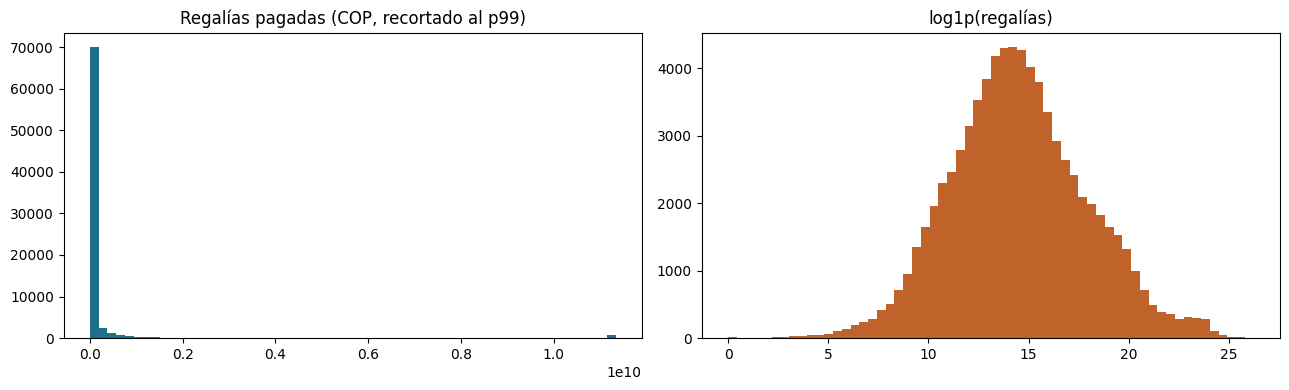

asimetría original: 28.5
asimetría con log: 0.14


In [10]:
base = df[df["contraprestacion"] == "REGALIAS"]

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(base["regalias"].clip(upper=base["regalias"].quantile(.99)), bins=60, color="#1f6f8b")
ax[0].set_title("Regalías pagadas (COP, recortado al p99)")
ax[1].hist(np.log1p(base["regalias"]), bins=60, color="#c0632b")
ax[1].set_title("log1p(regalías)")
plt.tight_layout()
plt.savefig("artifacts/figs/objetivo.png", dpi=120)
plt.show()

print("asimetría original:", round(stats.skew(base["regalias"]), 1))
print("asimetría con log:", round(stats.skew(np.log1p(base["regalias"])), 2))

### Posibles sesgos

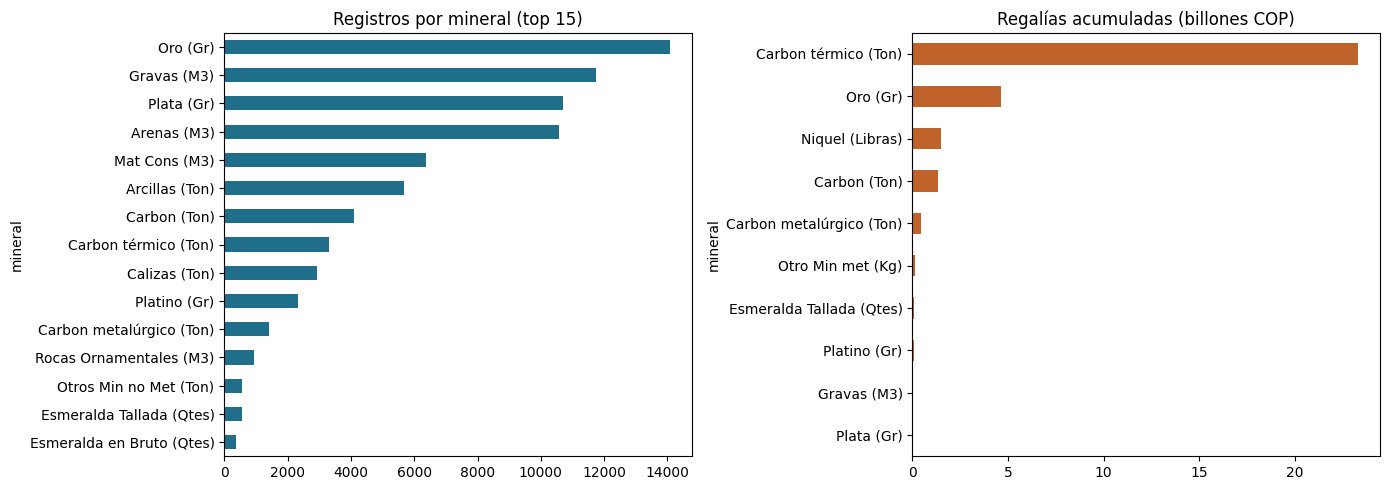

grandes proyectos, % de registros: 3.2
grandes proyectos, % del valor: 77.4
anio
2012    4319
2013    5607
2014    4911
2015    4858
2016    5304
2017    5367
2018    5375
2019    5214
2020    4161
2021    4546
2022    4821
2023    6104
2024    5983
2025    6393
2026    4785
Name: count, dtype: Int64


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
base["mineral"].value_counts().head(15).plot.barh(ax=ax[0], color="#1f6f8b")
ax[0].set_title("Registros por mineral (top 15)")
ax[0].invert_yaxis()

total_mineral = base.groupby("mineral")["regalias"].sum() / 1e12
total_mineral.sort_values(ascending=False).head(10).plot.barh(ax=ax[1], color="#c0632b")
ax[1].set_title("Regalías acumuladas (billones COP)")
ax[1].invert_yaxis()
plt.tight_layout()
plt.savefig("artifacts/figs/sesgos.png", dpi=120)
plt.show()

es_grande = base["nombre_del_proyecto"] != "PRODUCTORES"
print("grandes proyectos, % de registros:", round(es_grande.mean() * 100, 1))
print("grandes proyectos, % del valor:", round(base.loc[es_grande, "regalias"].sum() / base["regalias"].sum() * 100, 1))
print(base["anio"].value_counts().sort_index())

Lo que se ve en los datos:

- La mayoría de registros son de oro, plata, gravas y arenas, pero casi toda la plata la pone el carbón. Un error en carbón pesa mucho más en pesos que uno en gravas.
- Los grandes proyectos (Drummond, Cerrejón, Cerro Matoso, Prodeco y otros) son el 3,2 % de los registros y el 77,4 % del valor pagado.
- La ANM dice que los datos son preliminares y se ajustan con el tiempo. 2026 todavía está incompleto.
- "Carbon (Ton)" deja de usarse desde 2024 y se separa en térmico y metalúrgico. Las esmeraldas aparecen en Bogotá hasta 2015 porque antes no se registraba el municipio de origen.
- El volumen lo declara el productor y la minería ilegal no aparece.

## 3. Preparación de los datos

### Selección de variables
Entradas: volumen, año, trimestre, mineral, departamento y una variable nueva, gran_proyecto, que indica si el registro es de un título individual o de productores agregados. El municipio se deja por fuera porque tiene 888 categorías y el departamento ya recoge buena parte de esa información.

Los registros de 2026 se apartan desde ya para usarlos como datos nuevos en el despliegue. No entran ni a entrenamiento ni a prueba.

In [12]:
df["gran_proyecto"] = np.where(df["nombre_del_proyecto"].str.upper() == "PRODUCTORES", "No", "Si")

num_cols = ["volumen", "anio", "trimestre_num"]
cat_cols = ["mineral", "nombre_departamento", "gran_proyecto"]
features = num_cols + cat_cols
target = "regalias"

### Reporte exploratorio con ydata-profiling

In [13]:
from ydata_profiling import ProfileReport

perfil_df = df[features + [target, "contraprestacion", "recurso_natural", "nombre_municipio"]]
profile = ProfileReport(perfil_df, title="Perfil - Regalías ANM", minimal=True)
profile.to_file("artifacts/reporte_ydata_profiling.html")
print(perfil_df.shape)

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

Summarize dataset:   0%|          | 0/15 [00:00<?, ?it/s, Describe variable: volumen]

Summarize dataset:   0%|          | 0/15 [00:00<?, ?it/s, Describe variable: anio]   

  0%|          | 0/10 [00:00<?, ?it/s]

Summarize dataset:   7%|▋         | 1/15 [00:00<00:00, 25.11it/s, Describe variable: trimestre_num]

Summarize dataset:  13%|█▎        | 2/15 [00:00<00:00, 42.13it/s, Describe variable: mineral]      

... (23 outputs left out)

Render HTML: 100%|██████████| 1/1 [00:00<00:00,  4.06it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file: 100%|██████████| 1/1 [00:00<00:00, 415.44it/s]

(79151, 10)


### Limpieza de errores

In [14]:
n = len(df)
df = df.drop_duplicates(subset=list(raw.columns))
print("duplicados eliminados:", n - len(df))

n = len(df)
df = df[df["contraprestacion"] == "REGALIAS"]
print("compensaciones excluidas:", n - len(df))

n = len(df)
df = df[df["regalias"] > 0]
print("regalías <= 0 eliminadas:", n - len(df))

# Rocas Ornamentales (M3) tiene 3 filas en toneladas
n = len(df)
unidad_comun = df.groupby("mineral")["unidad_medida"].transform(lambda u: u.mode()[0])
df = df[df["unidad_medida"] == unidad_comun]
print("filas con unidad inconsistente:", n - len(df))

print("volúmenes escritos como '- 0':", raw["volumenes_de_explotacion"].str.contains("- 0").sum())

duplicados eliminados: 4
compensaciones excluidas: 1403
regalías <= 0 eliminadas: 9
filas con unidad inconsistente: 3
volúmenes escritos como '- 0': 4172


### Limpieza de nulos
Un volumen en cero con regalía mayor a cero no tiene sentido, así que se toma como dato faltante. No lo imputé porque el volumen es justo la variable que más explica la regalía, y rellenarlo con una mediana metería una relación falsa. Esas filas se eliminan (3,56 %). Igual el pipeline tiene SimpleImputer por si en producción llega algún dato vacío.

In [15]:
df.loc[df["volumen"] <= 0, "volumen"] = np.nan
print((df[features + [target]].isna().mean() * 100).round(2))

volumen                3.56
anio                   0.00
trimestre_num          0.00
mineral                0.00
nombre_departamento    0.00
gran_proyecto          0.00
regalias               0.00
dtype: float64


In [16]:
df = df.dropna(subset=["volumen"])

nuevos = df[df["anio"] == 2026].copy()
modelo_df = df[df["anio"] < 2026].copy()
print("para modelar:", len(modelo_df))
print("datos nuevos 2026:", len(nuevos))

para modelar: 70473
datos nuevos 2026: 4490


### Codificación
Mineral, departamento y gran_proyecto son nominales, no tienen orden, así que van con One-Hot Encoding. Las categorías con menos de 20 registros se agrupan como "infrequent". Al volumen se le aplica log1p y después se estandariza junto con año y trimestre.

La partición 70/30 se hace estratificada por mineral para que todos los minerales queden en entrenamiento y en prueba.

In [17]:
num_pipe = Pipeline([
    ("imputar", SimpleImputer(strategy="median")),
    ("log_vol", ColumnTransformer([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one"), [0])],
                                  remainder="passthrough")),
    ("escalar", StandardScaler()),
])
cat_pipe = Pipeline([
    ("imputar", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False)),
])
preprocesador = ColumnTransformer([("num", num_pipe, num_cols), ("cat", cat_pipe, cat_cols)])

X = modelo_df[features]
y = np.log1p(modelo_df[target])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=SEED,
                                                    stratify=modelo_df["mineral"])
print("train:", X_train.shape, " test:", X_test.shape)

Xt = preprocesador.fit_transform(X_train)
print("columnas después de codificar:", Xt.shape[1])

train: (49331, 6)  test: (21142, 6)


columnas después de codificar: 64


### Relaciones lineales y no lineales
Comparo Pearson (relación lineal), Spearman (relación monótona) e información mutua (cualquier tipo de dependencia).

In [18]:
tmp = X_train.copy()
tmp["log_reg"] = y_train
tmp["log_vol"] = np.log1p(tmp["volumen"])

filas = []
for c in ["volumen", "log_vol", "anio", "trimestre_num"]:
    filas.append([c, stats.pearsonr(tmp[c], tmp["log_reg"])[0], stats.spearmanr(tmp[c], tmp["log_reg"])[0]])
correlaciones = pd.DataFrame(filas, columns=["variable", "Pearson", "Spearman"]).round(3)
correlaciones

,variable,Pearson,Spearman
0,volumen,0.212,0.791
1,log_vol,0.810,0.791
2,anio,0.083,0.078
3,trimestre_num,0.007,0.006


In [19]:
mi_X = pd.get_dummies(X_train[cat_cols]).astype(int)
mi_X[["log_vol", "anio", "trimestre_num"]] = tmp[["log_vol", "anio", "trimestre_num"]].values
muestra = mi_X.sample(15000, random_state=SEED)   # con todo el train se demora mucho
mi = mutual_info_regression(muestra, y_train.loc[muestra.index], random_state=SEED)
mi = pd.Series(mi, index=mi_X.columns).sort_values(ascending=False)
mi.head(10).round(3)

log_vol                         1.171
mineral_Oro (Gr)                0.123
mineral_Plata (Gr)              0.088
gran_proyecto_Si                0.067
gran_proyecto_No                0.067
mineral_Carbon térmico (Ton)    0.054
mineral_Arenas (M3)             0.042
mineral_Carbon (Ton)            0.038
mineral_Gravas (M3)             0.037
nombre_departamento_Cesar       0.026
dtype: float64

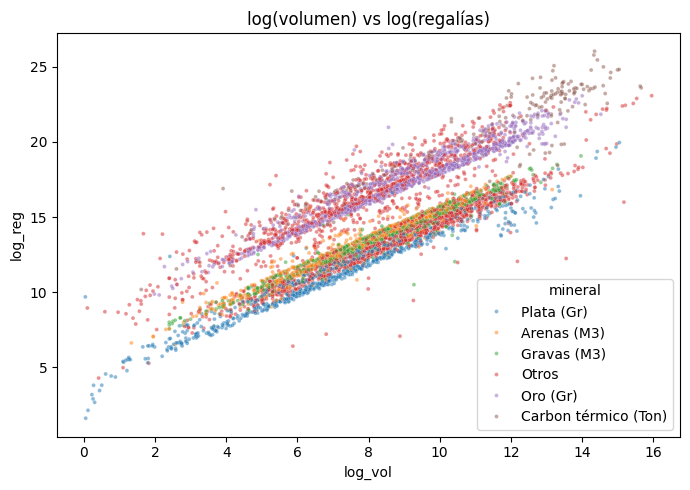

In [20]:
s = tmp.sample(6000, random_state=SEED)
principales = ["Oro (Gr)", "Carbon térmico (Ton)", "Gravas (M3)", "Plata (Gr)", "Arenas (M3)"]
mineral_s = modelo_df.loc[s.index, "mineral"]
s = s.assign(mineral=mineral_s.where(mineral_s.isin(principales), "Otros"))

fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=s, x="log_vol", y="log_reg", hue="mineral", s=8, alpha=.5, ax=ax)
ax.set_title("log(volumen) vs log(regalías)")
plt.tight_layout()
plt.savefig("artifacts/figs/relaciones.png", dpi=120)
plt.show()

El volumen tal cual casi no tiene correlación lineal con las regalías (Pearson 0,21) porque mezcla gramos de oro con toneladas de carbón. Spearman sí es alto (0,79), o sea que la relación es monótona pero no lineal. Con log(volumen) Pearson sube a 0,81. En la gráfica se ve una recta por cada mineral, casi paralelas pero con distinto intercepto, que vendría siendo el precio base de cada uno. Esa interacción entre mineral y volumen la deberían captar mejor los árboles y el boosting que un modelo lineal.

### Reducción de dimensiones

In [21]:
pca = PCA().fit(Xt)
var_acum = np.cumsum(pca.explained_variance_ratio_)
print("componentes para el 95 % de la varianza:", np.argmax(var_acum >= .95) + 1, "de", Xt.shape[1])

componentes para el 95 % de la varianza: 25 de 64


No apliqué PCA. Son 64 columnas para 49.331 registros de entrenamiento, así que la dimensión no es un problema, y la mayoría son dummies que se pueden interpretar (un mineral, un departamento). Con PCA harían falta 25 componentes para el 95 % de la varianza y cada una mezclaría minerales y departamentos, lo que le quita sentido al modelo para quien fiscaliza.

### Balanceo
No aplica porque es un problema de regresión. Lo que hice para que los minerales poco frecuentes no queden por fuera fue estratificar la partición por mineral.

## 4. Modelamiento

### Modelos clásicos
Validación cruzada de 5 folds sobre el 70 % de entrenamiento, con los hiperparámetros por defecto.

In [22]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}

def armar(modelo):
    return Pipeline([("prep", preprocesador), ("model", modelo)])

clasicos = {
    "Regresión lineal": (LinearRegression(), "por defecto"),
    "Ridge": (Ridge(alpha=1.0), "alpha=1.0"),
    "KNN": (KNeighborsRegressor(n_neighbors=5), "n_neighbors=5, weights=uniform"),
    "Árbol de decisión": (DecisionTreeRegressor(random_state=SEED), "max_depth=None, min_samples_leaf=1"),
    "SVR lineal": (LinearSVR(C=1.0, epsilon=0.0, max_iter=5000, random_state=SEED), "C=1.0, epsilon=0"),
}

resultados_cv = []
rmse_folds = {}
for nombre, (modelo, hp) in clasicos.items():
    inicio = time.time()
    r = cross_validate(armar(modelo), X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rmse_folds[nombre] = -r["test_rmse"]
    resultados_cv.append({"Modelo": nombre, "Hiperparámetros iniciales": hp, "Métrica": "RMSE (log)",
                          "CV Mean": -r["test_rmse"].mean(), "CV Std": r["test_rmse"].std(),
                          "R2 CV": r["test_r2"].mean(), "seg": round(time.time() - inicio, 1)})

cv_clasicos = pd.DataFrame(resultados_cv).sort_values("CV Mean")
cv_clasicos.round(4)

,Modelo,Hiperparámetros iniciales,Métrica,CV Mean,CV Std,R2 CV,seg
1,Ridge,alpha=1.0,RMSE (log),0.5719,0.0132,0.9705,0.4
0,Regresión lineal,por defecto,RMSE (log),0.5719,0.0131,0.9705,2.6
4,SVR lineal,"C=1.0, epsilon=0",RMSE (log),0.5885,0.0125,0.9688,2.3
3,Árbol de decisión,"max_depth=None, min_samples_leaf=1",RMSE (log),0.6556,0.0168,0.9613,1.4
2,KNN,"n_neighbors=5, weights=uniform",RMSE (log),0.6636,0.0136,0.9603,5.4


Sin ajustar nada, regresión lineal y Ridge quedan de primeras (RMSE alrededor de 0,572). El árbol sin límite de profundidad se sobreajusta (0,656) y KNN con k=5 sale ruidoso (0,664), en parte porque casi todas las columnas son dummies.

### Ajuste de hiperparámetros
La métrica para escoger es el RMSE sobre log(regalías). En pesos, el RMSE quedaría dominado por unos pocos pagos gigantes de carbón. En escala log el error es relativo, así que un productor pequeño y uno grande pesan igual. Además el RMSE castiga más los errores grandes que el MAE, y esos son los que interesan para encontrar pagos raros.

Uso GridSearchCV en los modelos con pocos hiperparámetros y RandomizedSearchCV en los ensambles. Siempre con los mismos 5 folds sobre el 70 % de entrenamiento; el test no se toca.

In [23]:
busquedas = {
    "Ridge": (Ridge(), {"model__alpha": [0.01, 0.1, 1, 10, 100]}),
    "KNN": (KNeighborsRegressor(), {"model__n_neighbors": [3, 5, 7, 10, 15, 25],
                                    "model__weights": ["uniform", "distance"]}),
    "Árbol de decisión": (DecisionTreeRegressor(random_state=SEED), {"model__max_depth": [6, 10, 15, 20, None],
                                                                    "model__min_samples_leaf": [1, 5, 10, 20, 50]}),
}

mejores = {}
for nombre, (modelo, grid) in busquedas.items():
    inicio = time.time()
    gs = GridSearchCV(armar(modelo), grid, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1)
    gs.fit(X_train, y_train)
    mejores[nombre] = gs
    print(nombre, gs.best_params_, "RMSE CV:", round(-gs.best_score_, 4), f"({time.time() - inicio:.0f} s)")

Ridge {'model__alpha': 0.1} RMSE CV: 0.5719 (2 s)


KNN {'model__n_neighbors': 7, 'model__weights': 'distance'} RMSE CV: 0.6385 (55 s)


Árbol de decisión {'model__max_depth': 20, 'model__min_samples_leaf': 5} RMSE CV: 0.5891 (21 s)


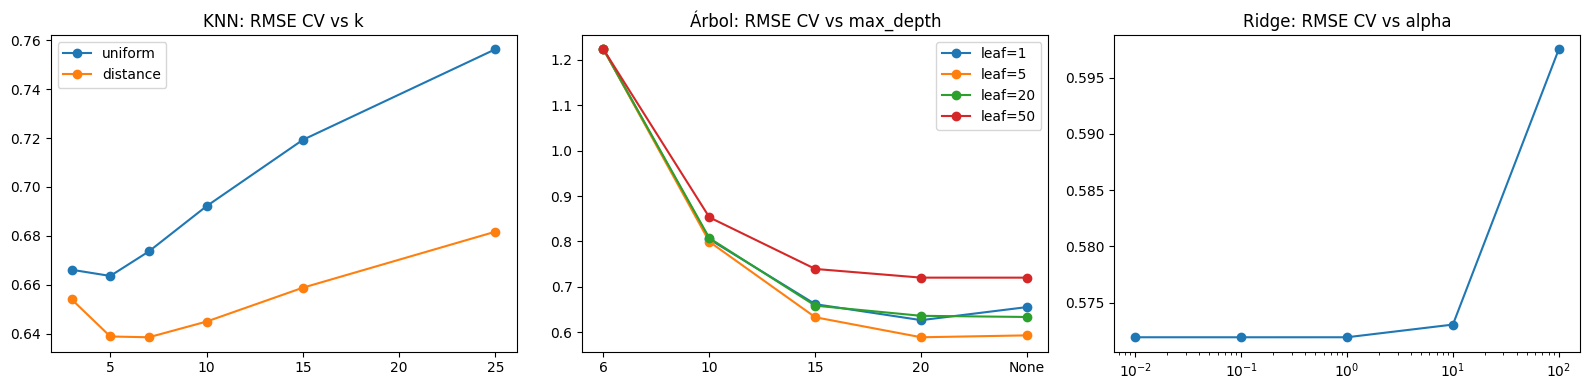

In [24]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

r = pd.DataFrame(mejores["KNN"].cv_results_)
for w in ["uniform", "distance"]:
    sub = r[r["param_model__weights"] == w]
    ax[0].plot(sub["param_model__n_neighbors"], -sub["mean_test_score"], "o-", label=w)
ax[0].set_title("KNN: RMSE CV vs k")
ax[0].legend()

r = pd.DataFrame(mejores["Árbol de decisión"].cv_results_)
for hoja in [1, 5, 20, 50]:
    sub = r[r["param_model__min_samples_leaf"] == hoja]
    ax[1].plot(sub["param_model__max_depth"].astype(str), -sub["mean_test_score"], "o-", label=f"leaf={hoja}")
ax[1].set_title("Árbol: RMSE CV vs max_depth")
ax[1].legend()

r = pd.DataFrame(mejores["Ridge"].cv_results_)
ax[2].semilogx(r["param_model__alpha"].astype(float), -r["mean_test_score"], "o-")
ax[2].set_title("Ridge: RMSE CV vs alpha")

plt.tight_layout()
plt.savefig("artifacts/figs/tuning_clasicos.png", dpi=120)
plt.show()

### Modelos de ensamble
- Votación: promedia Ridge, KNN y el árbol ya ajustados. La idea es mezclar un modelo lineal con dos no lineales.
- Bagging: muchos árboles entrenados con muestras bootstrap; al promediarlos baja la varianza del árbol.
- Boosting: HistGradientBoostingRegressor, que va agregando árboles que corrigen los errores de los anteriores. Escogí la versión con histogramas porque es mucho más rápida con 49 mil filas.

In [25]:
voting = armar(VotingRegressor([
    ("ridge", mejores["Ridge"].best_estimator_.named_steps["model"]),
    ("knn", mejores["KNN"].best_estimator_.named_steps["model"]),
    ("tree", mejores["Árbol de decisión"].best_estimator_.named_steps["model"]),
]))
inicio = time.time()
r = cross_validate(voting, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
rmse_folds["Votación"] = -r["test_rmse"]
print("Votación RMSE CV:", round(-r["test_rmse"].mean(), 4), f"({time.time() - inicio:.0f} s)")

Votación RMSE CV: 0.5176 (6 s)


In [26]:
bagging = armar(BaggingRegressor(estimator=DecisionTreeRegressor(random_state=SEED), random_state=SEED, n_jobs=1))
param_bag = {
    "model__n_estimators": [20, 40, 80],
    "model__max_samples": [0.5, 0.8, 1.0],
    "model__max_features": [0.6, 0.8, 1.0],
    "model__estimator__min_samples_leaf": [1, 3, 5],
}
inicio = time.time()
bag_search = RandomizedSearchCV(bagging, param_bag, n_iter=10, cv=cv, scoring="neg_root_mean_squared_error",
                                n_jobs=-1, random_state=SEED)
bag_search.fit(X_train, y_train)
mejores["Bagging"] = bag_search
print(bag_search.best_params_, round(-bag_search.best_score_, 4), f"({time.time() - inicio:.0f} s)")

{'model__n_estimators': 40, 'model__max_samples': 0.8, 'model__max_features': 1.0, 'model__estimator__min_samples_leaf': 1} 0.5051 (93 s)


In [27]:
boosting = armar(HistGradientBoostingRegressor(random_state=SEED))
param_hgb = {
    "model__learning_rate": [0.03, 0.05, 0.1, 0.2],
    "model__max_iter": [200, 400, 700],
    "model__max_leaf_nodes": [15, 31, 63],
    "model__min_samples_leaf": [10, 20, 50],
    "model__l2_regularization": [0.0, 0.1, 1.0],
}
inicio = time.time()
hgb_search = RandomizedSearchCV(boosting, param_hgb, n_iter=15, cv=cv, scoring="neg_root_mean_squared_error",
                                n_jobs=-1, random_state=SEED)
hgb_search.fit(X_train, y_train)
mejores["Boosting (HistGB)"] = hgb_search
print(hgb_search.best_params_, round(-hgb_search.best_score_, 4), f"({time.time() - inicio:.0f} s)")

{'model__min_samples_leaf': 10, 'model__max_leaf_nodes': 63, 'model__max_iter': 700, 'model__learning_rate': 0.1, 'model__l2_regularization': 0.1} 0.4782 (171 s)


In [28]:
# RMSE de cada fold para la mejor combinación de cada búsqueda
def folds_mejor(busqueda):
    res = busqueda.cv_results_
    i = busqueda.best_index_
    return np.array([-res[f"split{k}_test_score"][i] for k in range(5)])

for nombre in ["Ridge", "KNN", "Árbol de decisión"]:
    rmse_folds[nombre + " (ajustado)"] = folds_mejor(mejores[nombre])
rmse_folds["Bagging"] = folds_mejor(mejores["Bagging"])
rmse_folds["Boosting (HistGB)"] = folds_mejor(mejores["Boosting (HistGB)"])

candidatos = ["Regresión lineal", "Ridge", "KNN", "Árbol de decisión", "SVR lineal",
              "Ridge (ajustado)", "KNN (ajustado)", "Árbol de decisión (ajustado)"]
mejor_clasico = min(candidatos, key=lambda k: rmse_folds[k].mean())
base_rmse = rmse_folds[mejor_clasico].mean()
print("mejor clásico:", mejor_clasico, round(base_rmse, 4))

filas = []
for nombre, tipo in [("Votación", "Voting (promedio)"), ("Bagging", "Bagging (árboles)"),
                     ("Boosting (HistGB)", "Boosting (gradiente)")]:
    m = rmse_folds[nombre].mean()
    mejora = 100 * (base_rmse - m) / base_rmse
    filas.append({"Modelo": nombre, "Tipo": tipo, "Desempeño (RMSE CV)": m, "CV Std": rmse_folds[nombre].std(),
                  "Mejora vs clásico": f"{mejora:+.1f}% vs {mejor_clasico}"})
ensambles = pd.DataFrame(filas)
ensambles.round(4)

mejor clásico: Ridge (ajustado) 0.5719


,Modelo,Tipo,Desempeño (RMSE CV),CV Std,Mejora vs clásico
0,Votación,Voting (promedio),0.5176,0.0153,+9.5% vs Ridge (ajustado)
1,Bagging,Bagging (árboles),0.5051,0.0185,+11.7% vs Ridge (ajustado)
2,Boosting (HistGB),Boosting (gradiente),0.4782,0.0142,+16.4% vs Ridge (ajustado)


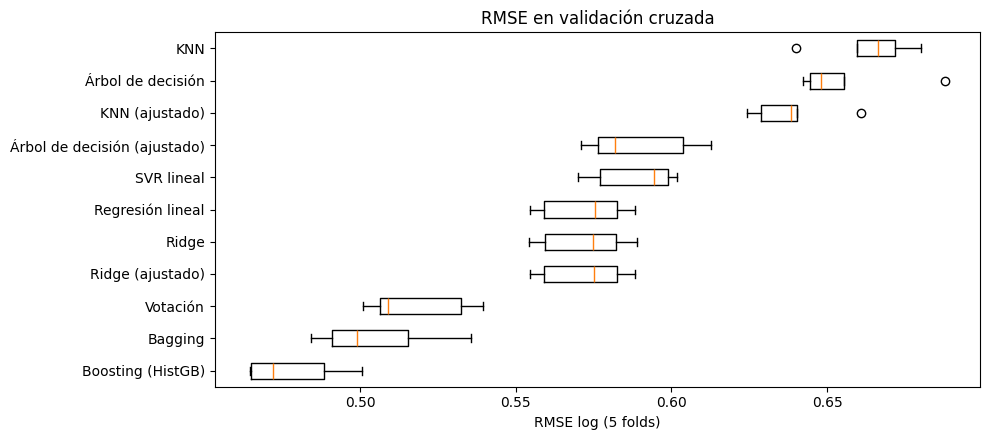

In [29]:
orden = sorted(rmse_folds, key=lambda k: rmse_folds[k].mean())
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.boxplot([rmse_folds[k] for k in orden], vert=False)
ax.set_yticklabels(orden)
ax.set_xlabel("RMSE log (5 folds)")
ax.set_title("RMSE en validación cruzada")
plt.tight_layout()
plt.savefig("artifacts/figs/cv_boxplot.png", dpi=120)
plt.show()

In [30]:
# rangos probados y valor elegido
filas = []
for nombre, busqueda in mejores.items():
    if hasattr(busqueda, "param_grid"):
        grid = busqueda.param_grid
    else:
        grid = busqueda.param_distributions
    for param, valores in grid.items():
        filas.append({"Modelo": nombre, "Hiperparámetro": param.replace("model__", ""),
                      "Rango probado": str(valores), "Valor final": busqueda.best_params_[param]})
hiperparametros = pd.DataFrame(filas)
hiperparametros

,Modelo,Hiperparámetro,Rango probado,Valor final
0,Ridge,alpha,"[0.01, 0.1, 1, 10, 100]",0.1
1,KNN,n_neighbors,"[3, 5, 7, 10, 15, 25]",7
2,KNN,weights,"['uniform', 'distance']",distance
3,Árbol de decisión,max_depth,"[6, 10, 15, 20, None]",20
4,Árbol de decisión,min_samples_leaf,"[1, 5, 10, 20, 50]",5
5,Bagging,n_estimators,"[20, 40, 80]",40
6,Bagging,max_samples,"[0.5, 0.8, 1.0]",0.8
7,Bagging,max_features,"[0.6, 0.8, 1.0]",1.0
8,Bagging,estimator__min_samples_leaf,"[1, 3, 5]",1
9,Boosting (HistGB),learning_rate,"[0.03, 0.05, 0.1, 0.2]",0.1


In [31]:
# para ver qué tanto movió el RMSE cada hiperparámetro: mejor y peor resultado según el valor
filas = []
for nombre, busqueda in mejores.items():
    res = pd.DataFrame(busqueda.cv_results_)
    for col in [c for c in res.columns if c.startswith("param_")]:
        por_valor = res.groupby(res[col].astype(str))["mean_test_score"].max() * -1
        filas.append({"Modelo": nombre, "Hiperparámetro": col.replace("param_model__", ""),
                      "Mejor valor": por_valor.idxmin(), "RMSE mejor": round(por_valor.min(), 4),
                      "RMSE peor": round(por_valor.max(), 4), "Δ RMSE": round(por_valor.max() - por_valor.min(), 4)})
efectos = pd.DataFrame(filas)
efectos

,Modelo,Hiperparámetro,Mejor valor,RMSE mejor,RMSE peor,Δ RMSE
0,Ridge,alpha,0.1,0.5719,0.5975,0.0256
1,KNN,n_neighbors,7,0.6385,0.6817,0.0432
2,KNN,weights,distance,0.6385,0.6636,0.0251
3,Árbol de decisión,max_depth,20,0.5891,1.2229,0.6338
4,Árbol de decisión,min_samples_leaf,5,0.5891,0.7204,0.1313
5,Bagging,n_estimators,40,0.5051,0.5084,0.0033
6,Bagging,max_samples,0.8,0.5051,0.6281,0.1230
7,Bagging,max_features,1.0,0.5051,1.0096,0.5045
8,Bagging,estimator__min_samples_leaf,1,0.5051,1.0114,0.5064
9,Boosting (HistGB),min_samples_leaf,10,0.4782,0.5064,0.0282


Qué controla cada hiperparámetro y qué pasó al moverlo (RMSE CV del peor al mejor valor):

- Ridge, alpha: la fuerza de la penalización L2. Entre 0,01 y 10 casi no cambia nada; con 100 empeora (0,598). Se queda en 0,1. Con 64 columnas y 49 mil filas no hay mucho que regularizar.
- KNN, n_neighbors y weights: cuántos vecinos se promedian y si los más cercanos pesan más. Con k=7 y pesos por distancia baja de 0,664 a 0,639. Con k muy grande se mezclan productores de tamaños muy distintos.
- Árbol, max_depth y min_samples_leaf: la profundidad y el tamaño mínimo de hoja. Es el que más cambia: con profundidad 6 da 1,22, y con profundidad 20 y hojas de 5 baja a 0,589. Exigir al menos 5 registros por hoja corrige el sobreajuste del árbol por defecto.
- Bagging: max_features y min_samples_leaf son los que más pesan. Si a un árbol le quitan columnas puede quedarse sin el volumen y el RMSE sube cerca de 1,0. max_samples=0,8 funcionó mejor que 0,5, y pasar de 20 a 80 árboles casi no cambia nada (0,003).
- Boosting: lo que más influyó fue la regularización L2 (de 0,518 a 0,478) y el número de hojas por árbol (de 0,511 a 0,478). max_iter y max_leaf_nodes quedaron en el valor más alto del rango, así que tal vez se gane algo ampliando el rango, aunque ya sería poco.

Los rangos se escogieron para ir de un modelo muy simple a uno que se sobreajusta, y en el caso de los ensambles se limitaron por tiempo de cómputo.

## 5. Evaluación con el conjunto de prueba
Todos los modelos se entrenan con el 70 % y se evalúan una sola vez en el 30 % de prueba. Saco las métricas en escala log y también en pesos.

In [32]:
finales = {
    "Regresión lineal": armar(LinearRegression()),
    "Ridge (ajustado)": mejores["Ridge"].best_estimator_,
    "KNN (ajustado)": mejores["KNN"].best_estimator_,
    "Árbol de decisión (ajustado)": mejores["Árbol de decisión"].best_estimator_,
    "SVR lineal": armar(clasicos["SVR lineal"][0]),
    "Votación": voting,
    "Bagging": mejores["Bagging"].best_estimator_,
    "Boosting (HistGB)": mejores["Boosting (HistGB)"].best_estimator_,
}

filas = []
pred_test = {}
for nombre, modelo in finales.items():
    modelo.fit(X_train, y_train)
    p = modelo.predict(X_test)
    pred_test[nombre] = p
    real_cop = np.expm1(y_test)
    pred_cop = np.expm1(p)
    filas.append({
        "Modelo": nombre,
        "MAE (log)": mean_absolute_error(y_test, p),
        "RMSE (log)": mean_squared_error(y_test, p) ** 0.5,
        "R2 (log)": r2_score(y_test, p),
        "MAE (MCOP)": mean_absolute_error(real_cop, pred_cop) / 1e6,
        "RMSE (MCOP)": mean_squared_error(real_cop, pred_cop) ** 0.5 / 1e6,
        "R2 (COP)": r2_score(real_cop, pred_cop),
        "MdAPE %": 100 * np.median(np.abs(pred_cop - real_cop) / real_cop),
    })

resultados_test = pd.DataFrame(filas).sort_values("RMSE (log)")
resultados_test.round(4)

,Modelo,MAE (log),RMSE (log),R2 (log),MAE (MCOP),RMSE (MCOP),R2 (COP),MdAPE %
7,Boosting (HistGB),0.2113,0.4672,0.9804,142.9989,1733.4075,0.8025,8.6619
6,Bagging,0.2158,0.4864,0.9788,142.5068,1803.3967,0.7862,7.3742
5,Votación,0.2567,0.5011,0.9775,152.4076,2172.1852,0.6899,12.4725
3,Árbol de decisión (ajustado),0.2715,0.5576,0.9721,155.6950,1888.4653,0.7656,11.6422
1,Ridge (ajustado),0.3061,0.5727,0.9706,197.0174,2839.6824,0.4700,17.5809
0,Regresión lineal,0.3060,0.5727,0.9706,197.0145,2839.6439,0.4700,17.5773
4,SVR lineal,0.2868,0.5909,0.9687,215.3328,2951.8848,0.4273,13.1113
2,KNN (ajustado),0.3495,0.6129,0.9663,162.2009,1958.7240,0.7478,17.5758


Para saber si la diferencia entre los dos mejores es real o es suerte de la partición hago tres cosas: un intervalo de confianza bootstrap del RMSE en test, la prueba de Wilcoxon sobre los errores absolutos (son pareados porque son los mismos registros) y una t pareada con los RMSE de los 5 folds.

In [33]:
modelo_1 = resultados_test["Modelo"].iloc[0]
modelo_2 = resultados_test["Modelo"].iloc[1]

rng = np.random.default_rng(SEED)
yt = y_test.values
idx = np.arange(len(yt))
boot_1, boot_2, dif = [], [], []
for _ in range(1000):
    b = rng.choice(idx, len(idx), replace=True)
    r1 = np.sqrt(np.mean((yt[b] - pred_test[modelo_1][b]) ** 2))
    r2 = np.sqrt(np.mean((yt[b] - pred_test[modelo_2][b]) ** 2))
    boot_1.append(r1)
    boot_2.append(r2)
    dif.append(r2 - r1)

print(modelo_1, "IC95 RMSE:", np.percentile(boot_1, [2.5, 97.5]).round(4))
print(modelo_2, "IC95 RMSE:", np.percentile(boot_2, [2.5, 97.5]).round(4))
print("IC95 de la diferencia:", np.percentile(dif, [2.5, 97.5]).round(4))

w = stats.wilcoxon(np.abs(yt - pred_test[modelo_1]), np.abs(yt - pred_test[modelo_2]))
print("Wilcoxon p =", w.pvalue)
t = stats.ttest_rel(rmse_folds[modelo_1], rmse_folds[modelo_2])
print("t pareada en CV: t =", round(t.statistic, 2), "p =", t.pvalue)

Boosting (HistGB) IC95 RMSE: [0.446 0.489]
Bagging IC95 RMSE: [0.4671 0.5079]
IC95 de la diferencia: [0.0108 0.0283]
Wilcoxon p = 2.7638134324185792e-11
t pareada en CV: t = -11.11 p = 0.0003738820244621843


El boosting tiene el menor RMSE en test (0,467) y también en validación cruzada (0,478). El intervalo de la diferencia con Bagging no pasa por cero y las dos pruebas dan p muy por debajo de 0,05, así que la diferencia es estadísticamente significativa. En pesos también le gana (R2 0,803 contra 0,786). Bagging tiene un error porcentual mediano un poco menor (7,4 % contra 8,7 %), pero se equivoca más en los pagos grandes, que son los que más importan al fiscalizar. Otra ventaja práctica es que el modelo de boosting pesa menos de 2 MB, mientras que Bagging tiene que guardar 40 árboles completos.

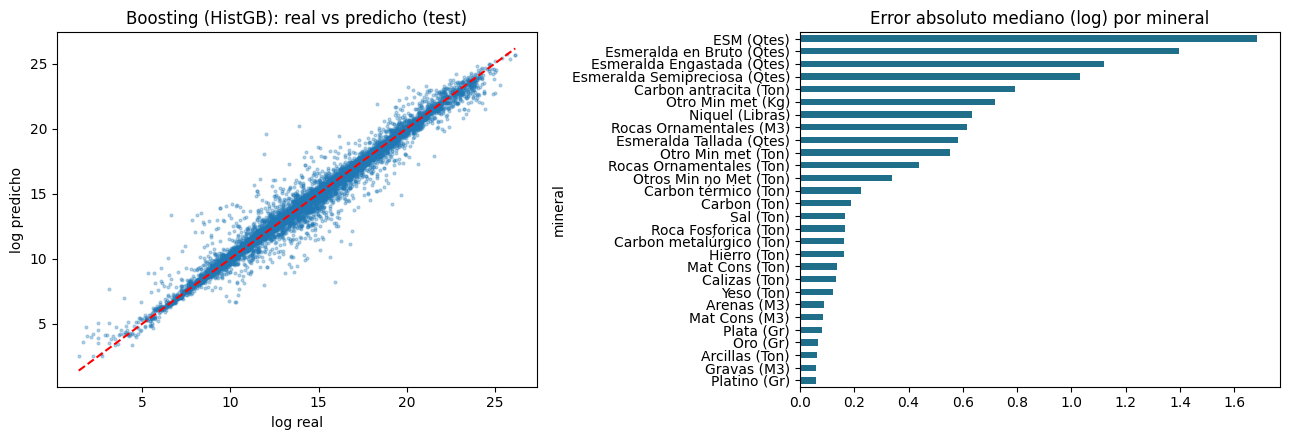

In [34]:
mejor_nombre = modelo_1
mejor = finales[mejor_nombre]
p = pred_test[mejor_nombre]

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(y_test, p, s=4, alpha=.3)
lim = [y_test.min(), y_test.max()]
ax[0].plot(lim, lim, "r--")
ax[0].set_xlabel("log real")
ax[0].set_ylabel("log predicho")
ax[0].set_title(mejor_nombre + ": real vs predicho (test)")

errores = pd.DataFrame({"mineral": X_test["mineral"], "error": np.abs(y_test - p)})
errores.groupby("mineral")["error"].median().sort_values().plot.barh(ax=ax[1], color="#1f6f8b")
ax[1].set_title("Error absoluto mediano (log) por mineral")
plt.tight_layout()
plt.savefig("artifacts/figs/eval_mejor.png", dpi=120)
plt.show()

## 6. Despliegue

Se guarda el pipeline completo (imputación, log, escalado, one-hot y modelo) dentro de un TransformedTargetRegressor. Así la app le pasa los datos tal cual y recibe la regalía directamente en pesos.

In [35]:
modelo_final = TransformedTargetRegressor(regressor=mejor, func=np.log1p, inverse_func=np.expm1, check_inverse=False)
modelo_final.fit(X_train, np.expm1(y_train))
joblib.dump(modelo_final, "model/modelo_regalias.joblib", compress=3)

info = {
    "modelo": mejor_nombre,
    "features_num": num_cols,
    "features_cat": cat_cols,
    "minerales": sorted(modelo_df["mineral"].unique()),
    "departamentos": sorted(modelo_df["nombre_departamento"].unique()),
    "anio_min": int(modelo_df["anio"].min()),
    "anio_max": int(modelo_df["anio"].max()),
    "rmse_log_test": float(resultados_test.iloc[0]["RMSE (log)"]),
    "r2_log_test": float(resultados_test.iloc[0]["R2 (log)"]),
    "mediana_volumen": modelo_df.groupby("mineral")["volumen"].median().round(2).to_dict(),
    "fuente": "https://www.datos.gov.co/d/r85m-vv6c",
}
with open("model/metadata.json", "w", encoding="utf-8") as f:
    json.dump(info, f, ensure_ascii=False, indent=2)

print("tamaño del modelo (MB):", round(os.path.getsize("model/modelo_regalias.joblib") / 1e6, 2))

tamaño del modelo (MB): 1.93


### Predicción con datos nuevos
Primero con los registros de 2026, que el modelo nunca vio, y después con algunos registros que armé a mano.

In [36]:
cargado = joblib.load("model/modelo_regalias.joblib")
pred_2026 = cargado.predict(nuevos[features])
real_2026 = nuevos[target].values

print("registros 2026:", len(nuevos))
print("R2 log:", round(r2_score(np.log1p(real_2026), np.log1p(pred_2026)), 3))
print("RMSE log:", round(mean_squared_error(np.log1p(real_2026), np.log1p(pred_2026)) ** 0.5, 3))
print("error porcentual mediano:", round(100 * np.median(np.abs(pred_2026 - real_2026) / real_2026), 1), "%")

registros 2026: 4490
R2 log: 0.965
RMSE log: 0.615
error porcentual mediano: 18.6 %


En 2026 el error sube un poco frente al test (RMSE 0,615 contra 0,467). Tiene sentido porque los precios base cambian cada periodo y el modelo tiene que extrapolar el año. Lo ideal sería reentrenarlo cada trimestre con lo que vaya publicando la ANM.

In [37]:
sinteticos = pd.DataFrame([
    {"mineral": "Carbon térmico (Ton)", "nombre_departamento": "Cesar", "gran_proyecto": "Si",
     "volumen": 3_500_000, "anio": 2026, "trimestre_num": 2},
    {"mineral": "Oro (Gr)", "nombre_departamento": "Antioquia", "gran_proyecto": "No",
     "volumen": 25_000, "anio": 2026, "trimestre_num": 1},
    {"mineral": "Gravas (M3)", "nombre_departamento": "Sucre", "gran_proyecto": "No",
     "volumen": 8_000, "anio": 2026, "trimestre_num": 3},
    {"mineral": "Calizas (Ton)", "nombre_departamento": "Boyaca", "gran_proyecto": "No",
     "volumen": 40_000, "anio": 2026, "trimestre_num": 2},
    {"mineral": "Esmeralda en Bruto (Qtes)", "nombre_departamento": "Boyaca", "gran_proyecto": "No",
     "volumen": 5_000, "anio": 2026, "trimestre_num": 4},
])
sinteticos["regalias_estimadas_cop"] = cargado.predict(sinteticos[features]).round(0)
sinteticos

,mineral,nombre_departamento,gran_proyecto,volumen,anio,trimestre_num,regalias_estimadas_cop
0,Carbon térmico (Ton),Cesar,Si,3500000,2026,2,4.728493e+10
1,Oro (Gr),Antioquia,No,25000,2026,1,2.825371e+08
2,Gravas (M3),Sucre,No,8000,2026,3,2.562977e+06
3,Calizas (Ton),Boyaca,No,40000,2026,2,4.238312e+06
4,Esmeralda en Bruto (Qtes),Boyaca,No,5000,2026,4,3.179576e+06


In [38]:
muestra_2026 = nuevos.sample(5, random_state=1)[features + [target]].copy()
muestra_2026["prediccion"] = cargado.predict(muestra_2026[features]).round(0)
muestra_2026

,volumen,anio,trimestre_num,mineral,nombre_departamento,gran_proyecto,regalias,prediccion
78422,5225.00,2026,3,Gravas (M3),Putumayo,No,1490542.00,1305155.0
74411,29440.01,2026,1,Mat Cons (M3),Valle del Cauca,No,2457603.00,3552569.0
953,1964.00,2026,1,Arenas (M3),Antioquia,No,624145.00,707901.0
692,914.89,2026,1,Oro (Gr),Antioquia,No,8611227.26,9850780.0
23941,1400.00,2026,1,Arcillas (Ton),Boyaca,No,375806.00,340135.0


In [39]:
# tablas que se usan en el informe
cv_clasicos.to_csv("artifacts/cv_clasicos.csv", index=False)
ensambles.to_csv("artifacts/ensambles.csv", index=False)
hiperparametros.to_csv("artifacts/hiperparametros.csv", index=False)
efectos.to_csv("artifacts/efectos_hp.csv", index=False)
resultados_test.to_csv("artifacts/test.csv", index=False)
sinteticos.to_csv("artifacts/predicciones_sinteticas.csv", index=False)
muestra_2026.to_csv("artifacts/predicciones_2026_muestra.csv", index=False)
nuevos.to_csv("data/datos_nuevos_2026.csv", index=False)

La app de Streamlit (app.py) carga model/modelo_regalias.joblib. Se puede ingresar un registro o subir un CSV, y si se pone lo que se pagó, la app avisa cuando el pago se aleja más de 2 RMSE de lo estimado.